# fydp-3 — EX-1 with Bi-LSTM, no demographics — **5-Fold Cross-Validation version**

**File tag:** `ex-1-with-bi-lstm-without-demographic-5fold`

This is the 5-fold version of the original `ex-1-with-bi-lstm-without-demographic` notebook.
The faculty asked for the **same 5-fold protocol in every experiment**, so all experiments can be
compared on common ground (single split vs 5-fold).

## What this experiment is
| Item | Value |
|---|---|
| Task | 3-class (Normal / Leve / Moderada), multinomial logistic regression head |
| Temporal pooling | Bi-LSTM (`bilstm`) |
| Demographic / symptom features | No |
| Fusion methods compared | `concat` vs `self_attention` |
| Best-checkpoint rule | highest validation macro-F1 |

## What changed (ONLY the training part)
- The old **single train / validation split** is replaced by **5-fold stratified, patient-level cross-validation** over the train + validation pool.
- The **test set is still the same fixed test set** from the `Split` column. CV never touches it. Every fold's model is evaluated on it.
- Results are reported as **mean ± std across the 5 folds**, plus a **fold-averaged (ensemble)** confusion matrix and ROC curve, plus a **paired permutation test** (same as ex-2).
- `quick_run()` is replaced by `build_model_and_train()` (trains one model on one fold) and a fold loop in Step 10.

## What did NOT change
Data loading, class labels, frame sampling (32 yemas / 16 palmas), image preprocessing, backbone,
fusion modules, classifier head, loss, optimizer (Adam, lr = 1e-4), batch size and the held-out test set.

## Settings kept the same as ex-2
`N_FOLDS = 5`, `CV_EPOCHS = 10`, `CV_RANDOM_STATE = 42`, `PERMUTATION_ITERS = 2000`.

**Compute note:** 2 fusion types × 5 folds × 10 epochs = **100 training epochs** in total. Run Step 10b and Step 10c as separate cells.

Every step is numbered. Run top to bottom.

## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [23]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

from sklearn.model_selection import StratifiedKFold   # NEW: needed for 5-fold CV

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")

Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [24]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      unas-palmas-yemas/
      metadata/
        metadata.csv
      dataset2/
        Dataset2.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed** — that's the
real, verified folder tree, so there's no guessing involved. Paste each path
in as a plain string (right up to the folder that directly contains the
`Leve` / `Moderada` / `Normal` class folders, or the CSV file itself for
`csv`). Leave any entry as `None` to fall back to auto-detection for just
that one item — but manual is the reliable option, use it if auto-detect has
failed before.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).

In [25]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":      "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv (Split, YEMAS/PALMAS/UNAS Path columns)
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",                     # <-- EDIT: exact path to metadata.csv (source of true Class one-hot columns)
    "yemas":    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":     "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
METADATA_CSV_PATH = MANUAL_PATHS["metadata"] or SPLIT_CSV_PATH
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "fydp-3_results", "cv_ex1_with_bilstm")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Multi-class label setup ---
CLASS_TO_IDX = {"Normal": 0, "Leve": 1, "Moderada": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_TO_IDX)

# --- Run settings ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "bilstm"   # "mean" or "bilstm"

# --- NEW: 5-fold cross-validation settings (identical to ex-2, so every experiment shares common ground) ---
N_FOLDS = 5              # patient-level StratifiedKFold over the train+validation pool
CV_EPOCHS = 10           # epochs per fold per fusion type (same value as ex-2)
CV_RANDOM_STATE = 42     # same seed in every experiment

# --- NEW: Significance testing settings (identical to ex-2) ---
PERMUTATION_ITERS = 2000
PERMUTATION_SEED = 42

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("METADATA_CSV_PATH:", METADATA_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print("CLASS_TO_IDX  :", CLASS_TO_IDX)
print(f"SUBSET_SIZE={SUBSET_SIZE}  N_FOLDS={N_FOLDS}  CV_EPOCHS={CV_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")

SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
METADATA_CSV_PATH: /kaggle/input/datasets/shimu080/metadata/metadata.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/fydp-3_results/cv_ex1_with_bilstm/2026-10-24 (writable Kaggle output area)
CLASS_TO_IDX  : {'Normal': 0, 'Leve': 1, 'Moderada': 2}
SUBSET_SIZE=None  N_FOLDS=5  CV_EPOCHS=10  BATCH_SIZE=16  TEMPORAL_POOLING=bilstm


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [26]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Moderada', 'Normal', 'Leve']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Moderada', 'Normal', 'Leve']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Moderada', 'Normal', 'Leve']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Split File + Metadata (true Class, integer-encoded label)

Same data-quality fix as the regression notebook: `Dataset2.csv`'s own `Class` column was found to
be **row-shifted (misaligned) for IDs 058-227** (~170 subjects) during verification — using it
directly would send those subjects' frame-loading code to the wrong class subfolder. So `Class` is
re-derived here from `metadata.csv`'s `Normal`/`Leve`/`Moderado` one-hot columns (verified ground
truth) instead, exactly as in the regression notebook.

**Classification-specific step:** the string `Class` (`Normal`/`Leve`/`Moderada`) is converted to an
integer label `y = CLASS_TO_IDX[Class]` (`0`/`1`/`2`) for `CrossEntropyLoss`, and class **inverse-
frequency weights** are computed from the training-set label distribution (set later, once `train_df`
exists in Step 5) to counteract the ~61% / 22% / 8% class imbalance.

The **`Split` column from `Dataset2.csv` is preserved unchanged** — it was verified to be
patient-ID-disjoint across train/validation/test and is not affected by the `Class` bug (only the
`Class` values in that one file were shifted, not `ID`/`Split`/path columns).

In [27]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )
if not os.path.isfile(METADATA_CSV_PATH):
    raise FileNotFoundError(
        f"Could not find metadata.csv (source of the true Class one-hot columns) at:\n  {METADATA_CSV_PATH}\n"
        f"Fix MANUAL_PATHS['metadata'] in Step 2."
    )

print("Using split file:", metadata_source)
print("Using metadata file (true Class one-hot columns):", METADATA_CSV_PATH)

split_df = pd.read_csv(metadata_source)
split_df = split_df.dropna(subset=["ID"]).copy()
split_df["ID"] = split_df["ID"].astype(str).str.strip()
assert "Split" in split_df.columns, "Split column missing from Dataset2.csv - cannot preserve the existing split."
split_df["Split"] = split_df["Split"].astype(str).str.strip()
# NOTE: Dataset2.csv's own "Class" / "Anemia Predict" columns are intentionally NOT used below -
# "Class" was found to be row-shifted/misaligned for IDs 058-227 during verification.
split_df = split_df[["ID", "Split"]]

meta_df = pd.read_csv(METADATA_CSV_PATH)
meta_df["ID"] = meta_df["ID"].astype(str).str.strip()
required_meta_cols = ["ID", "Normal", "Leve", "Moderado", "Hemoglobina"]
missing_meta_cols = [c for c in required_meta_cols if c not in meta_df.columns]
assert not missing_meta_cols, f"metadata.csv is missing required columns: {missing_meta_cols}"

# Re-derive Class from the one-hot columns (ground truth), instead of trusting any pre-existing
# Class column from Dataset2.csv.
def _derive_class(row):
    if row["Normal"] == 1:
        return "Normal"
    if row["Leve"] == 1:
        return "Leve"
    if row["Moderado"] == 1:
        return "Moderada"
    return None

meta_df["Class"] = meta_df.apply(_derive_class, axis=1)
assert meta_df["Class"].notna().all(), "Some metadata rows have no Normal/Leve/Moderado flag set - cannot derive Class."

# Drop physiologically-impossible Hemoglobina values (data-entry errors) - these rows are unreliable
# regardless of target, so they're dropped rather than silently corrected/guessed.
HB_MIN_PLAUSIBLE, HB_MAX_PLAUSIBLE = 3.0, 20.0
outlier_mask = (meta_df["Hemoglobina"] < HB_MIN_PLAUSIBLE) | (meta_df["Hemoglobina"] > HB_MAX_PLAUSIBLE)
n_outliers = int(outlier_mask.sum())
if n_outliers:
    print(f"Dropping {n_outliers} subject(s) with implausible Hemoglobina values "
          f"(outside [{HB_MIN_PLAUSIBLE}, {HB_MAX_PLAUSIBLE}] g/dL):")
    print(meta_df.loc[outlier_mask, ["ID", "Hemoglobina"]].to_string(index=False))
meta_df = meta_df.loc[~outlier_mask].reset_index(drop=True)

# Integer-encode the label for CrossEntropyLoss.
meta_df["Label"] = meta_df["Class"].map(CLASS_TO_IDX)
assert meta_df["Label"].notna().all(), "Some Class values did not map via CLASS_TO_IDX - check spelling/casing."
meta_df["Label"] = meta_df["Label"].astype(int)

# Merge: keep the ORIGINAL Split assignment (from Dataset2.csv), attach the corrected Class + Label.
metadata_df = split_df.merge(meta_df[["ID", "Class", "Label"]], on="ID", how="inner")
n_dropped_no_meta = len(split_df) - len(metadata_df)
if n_dropped_no_meta:
    print(f"NOTE: {n_dropped_no_meta} subject(s) in the split file had no matching metadata row "
          f"(dropped due to outlier removal above, or ID not present in metadata.csv).")

has_split_col = True
print(f"\n{len(metadata_df)} subjects with a valid Split + Class label.")
print(metadata_df["Split"].value_counts())
print("\nClass distribution:")
print(metadata_df["Class"].value_counts())


Using split file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
Using metadata file (true Class one-hot columns): /kaggle/input/datasets/shimu080/metadata/metadata.csv
Dropping 2 subject(s) with implausible Hemoglobina values (outside [3.0, 20.0] g/dL):
   ID  Hemoglobina
ID645        123.0
ID843        140.0
NOTE: 2 subject(s) in the split file had no matching metadata row (dropped due to outlier removal above, or ID not present in metadata.csv).

907 subjects with a valid Split + Class label.
Split
train         634
validation    137
test          136
Name: count, dtype: int64

Class distribution:
Class
Normal      621
Leve        211
Moderada     75
Name: count, dtype: int64


## Step 5 — Existence Check + Build Fixed Test Set + Train/Val Pool for CV

- Existence check (per-subject, all 3 modality files present) is unchanged.
- **New split structure for CV:** the `Split` column's `train` and `validation` rows are combined
  into a single **`trainval_df`** pool that Step 10's K-Fold loop will re-split internally (5 folds
  by default). The `test` rows become **`test_df`**, held out completely — never touched by CV,
  used only for final per-fold evaluation — so results stay comparable to the single-split
  notebooks.
- Patient-ID disjointness between `trainval_df` and `test_df` is asserted, same as before.

In [28]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Class"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

assert has_split_col, "Step 4 requires the Split column from Dataset2.csv to exist."
trainval_df = usable_df[usable_df["Split"].isin(["train", "validation"])].reset_index(drop=True)
test_df = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)

trainval_ids, test_ids = set(trainval_df["ID"]), set(test_df["ID"])
assert trainval_ids.isdisjoint(test_ids)
print("PASS: trainval and test are patient-level disjoint.")

print(f"\ntrainval (train+validation, re-split by 5-fold CV in Step 10) = {len(trainval_df)}")
print(f"test (held out, untouched by CV)                              = {len(test_df)}")
print("\ntrainval class counts:\n", trainval_df["Class"].value_counts())
print("\ntest class counts:\n", test_df["Class"].value_counts())
print("\n(Class weights are computed separately inside each fold in Step 10, from that fold's training labels only.)")

Checking files exist:   0%|          | 0/907 [00:00<?, ?it/s]


808 / 907 subjects have all 3 modality inputs on disk.
PASS: trainval and test are patient-level disjoint.

trainval (train+validation, re-split by 5-fold CV in Step 10) = 685
test (held out, untouched by CV)                              = 123

trainval class counts:
 Class
Normal      458
Leve        164
Moderada     63
Name: count, dtype: int64

test class counts:
 Class
Normal      87
Leve        29
Moderada     7
Name: count, dtype: int64

(Class weights are computed separately inside each fold in Step 10, from that fold's training labels only.)


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class

Unchanged: frame sampling, resize, ImageNet normalization, augmentation-free preprocessing exactly
as in the original notebooks (32 yemas frames, 16 palmas frames, evenly sampled from pre-extracted
folders, no on-the-fly video decoding).

**Classification change:** `__getitem__` now returns `label = torch.tensor(int(row["Label"]), dtype=torch.long)`
— a single class index in `{0, 1, 2}` — instead of a continuous Hb value or a 0/1 binary flag.

In [29]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)
        # Multi-class label: 0=Normal, 1=Leve, 2=Moderada.
        label = torch.tensor(int(row["Label"]), dtype=torch.long)
        return yemas, palmas, unas, label

# Sanity check on one real subject before committing to a full run
_sample_row = trainval_df.iloc[0]
_sample_ds = TriModalDataset(trainval_df.iloc[[0]], frame_transform)
_y, _p, _u, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} "
      f"palmas={tuple(_p.shape)} unas={tuple(_u.shape)} label={_l.item()} ({IDX_TO_CLASS[_l.item()]})")
print("TriModalDataset ready (loading pre-extracted frames, no video decoding).")

Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) label=0 (Normal)
TriModalDataset ready (loading pre-extracted frames, no video decoding).


## Step 7 — Model Building Blocks (Encoder, Temporal Pool, Fusion)

Unchanged from both prior notebooks. Two fusion modes side by side: `ConcatFusion` (baseline, no
learned interaction) and `SelfAttentionFusion` (proposed — 3 modality tokens attend to each other,
then mean-pooled).

In [30]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction."""
    def __init__(self, embed_dim=256):
        super().__init__()
        self.out_dim = embed_dim * 3

    def forward(self, v_yemas, v_palmas, v_unas):
        return torch.cat([v_yemas, v_palmas, v_unas], dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the 3 modality tokens attend to each other symmetrically."""
    def __init__(self, embed_dim=256, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(3, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, v_yemas, v_palmas, v_unas):
        x = torch.stack([v_yemas, v_palmas, v_unas], dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready.")


Model building blocks ready.


## Step 8 — Full Model + Train/Eval Functions (Multinomial Logistic Regression Head + Metrics)

`fydp_3Model`'s architecture (encoders, temporal pooling, fusion) is **unchanged**. What changes
is the classifier head and everything downstream of it:
- Final layer: `Linear(hidden, 1)` -> **`Linear(hidden, NUM_CLASSES)`** (3 raw logits, one per class —
  no activation applied here; `nn.CrossEntropyLoss` applies log-softmax internally, which is exactly
  the multinomial-logistic-regression setup: softmax generalizes binary logistic regression's sigmoid
  to >2 classes).
- `criterion`: `nn.MSELoss()` -> **`nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)`** — the multi-class
  generalization of the original notebook's imbalance-weighted `BCEWithLogitsLoss`.
- `evaluate()`: drops MAE/MSE/RMSE/R²/Pearson and computes **accuracy, macro-precision, macro-recall,
  macro-F1, macro one-vs-rest ROC-AUC**, and returns the raw predicted class indices, true labels, and
  softmax probabilities (needed later for ROC curves and the confusion matrix).
- Best-checkpoint selection: lowest validation MAE -> **highest validation macro-F1** — macro-F1
  weights Normal/Leve/Moderada equally, so the checkpoint isn't picked purely by how well it predicts
  the majority "Normal" class.

**5-fold change:** `quick_run()` is gone. It is replaced by **`build_model_and_train()`**, which trains
**one model on one fold** (same optimizer, loss and best-checkpoint rule as before). The loop over the
5 folds lives in Step 10.

In [31]:
class fydp_3Model(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3, num_classes=NUM_CLASSES):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.fusion = ConcatFusion(embed_dim) if fusion == "concat" else SelfAttentionFusion(embed_dim, dropout=dropout)
        hidden = 128 if fusion == "concat" else 64
        # Multinomial logistic regression head: NUM_CLASSES raw logits, no activation here -
        # nn.CrossEntropyLoss applies log-softmax internally during training.
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, num_classes)
        )

    def forward(self, yemas, palmas, unas):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        fused = self.fusion(v_yemas, v_palmas, v_unas)
        return self.classifier(fused)  # raw logits, shape (B, NUM_CLASSES)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Multi-class classification metrics: accuracy, macro precision/recall/F1, macro one-vs-rest
    ROC-AUC, and the confusion matrix - replacing the regression metric set (MAE/MSE/RMSE/R2/Pearson)."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        logits = model(yemas, palmas, unas)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(F.softmax(logits, dim=1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = probs.argmax(axis=1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    try:
        # One-vs-rest macro AUC; needs >=2 classes present with >=1 sample each in `labels`.
        y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_macro = float("nan")  # e.g. a class missing entirely from this split

    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": float(acc),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "auc_macro_ovr": float(auc_macro),
    }
    return metrics, preds, labels, probs, cm


def build_model_and_train(fusion_name, fold_train_df, fold_val_df, fold_class_weights, epochs,
                          temporal_pooling=TEMPORAL_POOLING):
    """Trains ONE model on ONE fold (this replaces quick_run(): it is called once per fold from
    Step 10). Same optimizer / loss / checkpoint rule as before: Adam lr=1e-4, class-weighted
    CrossEntropy, best checkpoint = highest validation macro-F1.
    Returns (model loaded with its best weights, per-epoch history DataFrame)."""
    loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(TriModalDataset(fold_train_df, frame_transform),
                               batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(TriModalDataset(fold_val_df, frame_transform),
                             batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

    model = fydp_3Model(fusion=fusion_name, temporal_pooling=temporal_pooling).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)
    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    history = []
    best_val_f1, best_state = -float("inf"), None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, _, _, _, _ = evaluate(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss,
                         "val_loss": val_metrics["loss"], "val_f1_macro": val_metrics["f1_macro"]})
        print(f"  Epoch {epoch}/{epochs}  train_loss(CE)={train_loss:.4f}  val_loss(CE)={val_metrics['loss']:.4f}  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_F1_macro={val_metrics['f1_macro']:.3f}  "
              f"val_AUC_macro={val_metrics['auc_macro_ovr']:.3f}")
        if val_metrics["f1_macro"] == val_metrics["f1_macro"] and val_metrics["f1_macro"] > best_val_f1:
            best_val_f1 = val_metrics["f1_macro"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


print("Training/eval utilities ready (multinomial logistic regression, one model per fold).")

Training/eval utilities ready (multinomial logistic regression, one model per fold).


## Step 10 — 5-Fold Cross-Validation Training Loop (Concat vs Self-Attention)

**This is the only part that changed compared with the single-split notebook.**

- **Step 10a — Fold setup (run once).** Makes the 5 stratified, patient-level splits of `trainval_df` once and stores them in `fold_splits`. Both fusion types use the **same** folds, which the paired permutation test in Step 11 needs. Do **not** re-run 10a between 10b and 10c.
- **Step 10b — Concat fusion, 5 folds.** For each fold:
  1. Split into this fold's train / validation subjects (patient-level, stratified).
  2. Compute **inverse-frequency class weights** from this fold's training labels only.
  3. Train for `CV_EPOCHS` epochs and keep the best checkpoint (highest validation macro-F1).
  4. Evaluate that checkpoint on the **fixed test set** and save the metrics and probabilities.
- **Step 10c — Self-attention fusion, 5 folds.** Exactly the same, with `self_attention`.
- **Step 10d — Combine + save.** Puts all fold results in `fold_results_df` and writes CSV files to `RESULTS_DIR`.

**Re-run safety (added):** Steps 10b and 10c now clear their own previous results at the top, so you can safely re-run either one (e.g. after a crash) without creating duplicate folds. After re-running either, always re-run **Step 10d** to rebuild `fold_results_df`. Do not re-run 10a unless you plan to re-run both 10b and 10c.

Cell A — setup (run once)

In [32]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_RANDOM_STATE)
test_loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))

trainval_labels = trainval_df["Label"].to_numpy()
fold_splits = list(skf.split(trainval_df, trainval_labels))  # shared by both fusion cells below

fold_results = []
fold_test_probs = {"concat": [], "self_attention": []}
fold_histories = {"concat": [], "self_attention": []}

Cell B — concat, 5-fold

In [34]:
import gc

fusion_name = "concat"

# --- RESET GUARD: makes this cell safe to re-run. Removes any rows/probs/histories left over
# --- from an earlier (crashed or repeated) run of THIS fusion type only, so nothing is duplicated.
fold_results = [r for r in fold_results if r["fusion"] != fusion_name]
fold_test_probs[fusion_name] = []
fold_histories[fusion_name] = []
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    fold_label_counts = fold_train_df["Label"].value_counts().sort_index()
    counts = np.array([fold_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
    inv_freq = counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None))
    fold_class_weights = torch.tensor(inv_freq, dtype=torch.float32)

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df,
                                               fold_class_weights, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1_macro={test_metrics['f1_macro']:.3f} AUC_macro={test_metrics['auc_macro_ovr']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if not k.startswith("per_class")
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))

    # free GPU memory before the next fold starts
    del model, criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


================ FUSION = concat ================

----- fold 1/5 (train=548 val=137) -----


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 1/10  train_loss(CE)=1.0721  val_loss(CE)=1.0358  val_acc=0.526  val_F1_macro=0.445  val_AUC_macro=0.692


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

... (151 outputs left out)

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 10/10  train_loss(CE)=0.2096  val_loss(CE)=1.6684  val_acc=0.569  val_F1_macro=0.442  val_AUC_macro=0.661


eval:   0%|          | 0/8 [00:00<?, ?it/s]

  fold 5 [concat] TEST: acc=0.537 F1_macro=0.321 AUC_macro=0.651


Cell C — self_attention, 5-fold

In [35]:
import gc

fusion_name = "self_attention"

# --- RESET GUARD: makes this cell safe to re-run. Removes any rows/probs/histories left over
# --- from an earlier (crashed or repeated) run of THIS fusion type only, so nothing is duplicated.
fold_results = [r for r in fold_results if r["fusion"] != fusion_name]
fold_test_probs[fusion_name] = []
fold_histories[fusion_name] = []
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    fold_label_counts = fold_train_df["Label"].value_counts().sort_index()
    counts = np.array([fold_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
    inv_freq = counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None))
    fold_class_weights = torch.tensor(inv_freq, dtype=torch.float32)

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df,
                                               fold_class_weights, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1_macro={test_metrics['f1_macro']:.3f} AUC_macro={test_metrics['auc_macro_ovr']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if not k.startswith("per_class")
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))

    # free GPU memory before the next fold starts
    del model, criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


================ FUSION = self_attention ================

----- fold 1/5 (train=548 val=137) -----


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 1/10  train_loss(CE)=1.0990  val_loss(CE)=1.0566  val_acc=0.628  val_F1_macro=0.378  val_AUC_macro=0.675


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

... (151 outputs left out)

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 10/10  train_loss(CE)=0.2870  val_loss(CE)=1.3811  val_acc=0.496  val_F1_macro=0.439  val_AUC_macro=0.677


eval:   0%|          | 0/8 [00:00<?, ?it/s]

  fold 5 [self_attention] TEST: acc=0.602 F1_macro=0.470 AUC_macro=0.720


Cell D — combine + save

In [36]:
# --- SANITY CHECK: each fusion must have exactly N_FOLDS results, one per fold 1..N_FOLDS ---
for _name in ["concat", "self_attention"]:
    _folds = sorted(r["fold"] for r in fold_results if r["fusion"] == _name)
    assert _folds == list(range(1, N_FOLDS + 1)), (
        f"[{_name}] expected folds {list(range(1, N_FOLDS + 1))} but found {_folds}. "
        f"Re-run the Step 10b/10c cell for '{_name}' (it now resets its own results automatically)."
    )
    assert len(fold_test_probs[_name]) == N_FOLDS and len(fold_histories[_name]) == N_FOLDS, (
        f"[{_name}] fold_test_probs / fold_histories do not have {N_FOLDS} entries - re-run its Step 10 cell."
    )
print("PASS: both fusion types have exactly", N_FOLDS, "folds.")

fold_results_df = pd.DataFrame(fold_results)
fold_results_df.to_csv(os.path.join(RESULTS_DIR, "cv_fold_results.csv"), index=False)
for fusion_name in ["concat", "self_attention"]:
    pd.concat(fold_histories[fusion_name], ignore_index=True).to_csv(
        os.path.join(RESULTS_DIR, f"{fusion_name}_cv_history.csv"), index=False
    )

print("\n\n=== Per-fold test results ===")
print(fold_results_df.to_string(index=False))

PASS: both fusion types have exactly 5 folds.


=== Per-fold test results ===
        fusion  fold     loss  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr
        concat     1 1.620875  0.691057         0.378618      0.386973  0.378272       0.706829
        concat     2 1.322216  0.585366         0.407543      0.419267  0.406212       0.725277
        concat     3 2.313225  0.650407         0.365942      0.367816  0.364859       0.616890
        concat     4 1.316005  0.666667         0.442308      0.426929  0.426969       0.676182
        concat     5 1.683189  0.536585         0.326923      0.321839  0.321364       0.651190
self_attention     1 1.278575  0.682927         0.355759      0.352490  0.337149       0.683098
self_attention     2 0.922830  0.682927         0.541414      0.516694  0.525215       0.764120
self_attention     3 0.977083  0.707317         0.592454      0.507389  0.512930       0.720214
self_attention     4 1.416610  0.674797         0.540139  

## Step 11 — Aggregate CV Results (Mean ± Std) + Paired Permutation Significance Test

Reports mean ± std of each test metric across the `N_FOLDS` folds, per fusion type — the headline
numbers to report, instead of a single-run point estimate.

Then runs a **paired sign-flip permutation test** (2000 iterations) on the per-fold macro-F1 scores
of `concat` vs `self_attention` (paired because both fusion types were evaluated on the exact same
folds/test set) to get a p-value for whether one fusion method's advantage is statistically
meaningful, rather than noise from a single lucky/unlucky split — mirroring BPANet's permutation-
test methodology.

In [37]:
summary_rows = []
for fusion_name in ["concat", "self_attention"]:
    sub = fold_results_df[fold_results_df["fusion"] == fusion_name]
    row = {"fusion": fusion_name}
    for metric in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr"]:
        row[f"{metric}_mean"] = sub[metric].mean()
        row[f"{metric}_std"] = sub[metric].std()
    summary_rows.append(row)
cv_summary_df = pd.DataFrame(summary_rows)
print("=== CV summary (mean +/- std across folds) ===")
print(cv_summary_df.to_string(index=False))
cv_summary_df.to_csv(os.path.join(RESULTS_DIR, "cv_summary_mean_std.csv"), index=False)


def paired_permutation_test(scores_a, scores_b, n_iter=PERMUTATION_ITERS, seed=PERMUTATION_SEED):
    """Sign-flip paired permutation test on the per-fold score differences (a - b). Returns
    (observed_mean_diff, two_sided_p_value)."""
    scores_a, scores_b = np.asarray(scores_a, dtype=np.float64), np.asarray(scores_b, dtype=np.float64)
    diffs = scores_a - scores_b
    observed = diffs.mean()
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_iter):
        signs = rng.choice([-1.0, 1.0], size=len(diffs))
        permuted_mean = (diffs * signs).mean()
        if abs(permuted_mean) >= abs(observed):
            count += 1
    p_value = (count + 1) / (n_iter + 1)
    return float(observed), float(p_value)


concat_f1 = fold_results_df.loc[fold_results_df["fusion"] == "concat", "f1_macro"].to_numpy()
selfattn_f1 = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", "f1_macro"].to_numpy()
assert len(concat_f1) == len(selfattn_f1) == N_FOLDS, (
    f"Fold counts mismatch: concat={len(concat_f1)}, self_attention={len(selfattn_f1)}, expected {N_FOLDS}. "
    "Re-run Step 10b/10c as needed, then Step 10d (it rebuilds fold_results_df)."
)

observed_diff, p_value = paired_permutation_test(selfattn_f1, concat_f1)
print(f"\n=== Paired permutation test: self_attention vs concat, macro-F1 per fold ===")
print(f"concat     per-fold F1_macro: {concat_f1.round(3).tolist()}")
print(f"self_attn  per-fold F1_macro: {selfattn_f1.round(3).tolist()}")
print(f"Observed mean difference (self_attention - concat): {observed_diff:+.4f}")
print(f"Two-sided permutation p-value ({PERMUTATION_ITERS} iterations): {p_value:.4f}")
if p_value < 0.05:
    print("=> Statistically significant difference at alpha=0.05.")
else:
    print("=> NOT statistically significant at alpha=0.05 - do not claim one fusion method is "
          "reliably better based on this sample size; consider more folds or seeds if this matters.")

with open(os.path.join(RESULTS_DIR, "permutation_test_result.json"), "w") as f:
    json.dump({"observed_diff_selfattn_minus_concat": observed_diff, "p_value": p_value,
                "n_iter": PERMUTATION_ITERS, "n_folds": N_FOLDS}, f, indent=2)

# --- Per-class metrics, averaged across folds ---
print("\n=== Per-class metrics (mean across folds) ===")
for fusion_name in ["concat", "self_attention"]:
    sub = fold_results_df[fold_results_df["fusion"] == fusion_name]
    # per_class_* columns are stored as lists inside fold_results (recovered from the raw metrics
    # dict); re-derive them here since fold_results_df dropped list-valued columns above.
    print(f"\n[{fusion_name}]")
    # Recompute directly from fold_test_probs + the fixed test_df labels for a clean per-class view.
    all_probs = np.mean(np.stack(fold_test_probs[fusion_name], axis=0), axis=0)  # fold-averaged probs
    all_preds = all_probs.argmax(axis=1)
    true_labels = test_df["Label"].to_numpy()
    prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
        true_labels, all_preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
    )
    for c in range(NUM_CLASSES):
        print(f"  [{IDX_TO_CLASS[c]:8s}] precision={prec_pc[c]:.3f}  recall={rec_pc[c]:.3f}  "
              f"f1={f1_pc[c]:.3f}  support={support_pc[c]}")

=== CV summary (mean +/- std across folds) ===
        fusion  accuracy_mean  accuracy_std  precision_macro_mean  precision_macro_std  recall_macro_mean  recall_macro_std  f1_macro_mean  f1_macro_std  auc_macro_ovr_mean  auc_macro_ovr_std
        concat       0.626016      0.063498              0.384267             0.043493           0.384565          0.042485       0.379535      0.040504            0.675274           0.043260
self_attention       0.669919      0.040077              0.500217             0.091517           0.460208          0.068937       0.459303      0.074708            0.714921           0.032677

=== Paired permutation test: self_attention vs concat, macro-F1 per fold ===
concat     per-fold F1_macro: [0.378, 0.406, 0.365, 0.427, 0.321]
self_attn  per-fold F1_macro: [0.337, 0.525, 0.513, 0.451, 0.47]
Observed mean difference (self_attention - concat): +0.0798
Two-sided permutation p-value (2000 iterations): 0.1784
=> NOT statistically significant at alpha=0.05 - do 

## Step 12 — Fold-Averaged Confusion Matrices + One-vs-Rest ROC Curves

Since the same fixed `test_df` was evaluated once per fold (with a differently-trained model each
time), the `N_FOLDS` softmax probability arrays for each fusion type are **averaged into a single
ensemble prediction** on the test set — a more sample-stable diagnostic than picking any single
fold's model. Confusion matrices and one-vs-rest ROC curves are plotted from these fold-averaged
probabilities, one panel per fusion method.

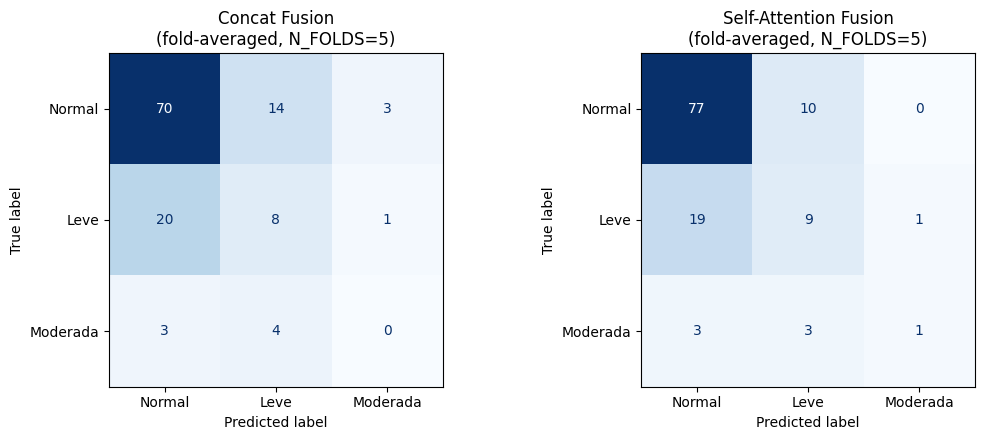

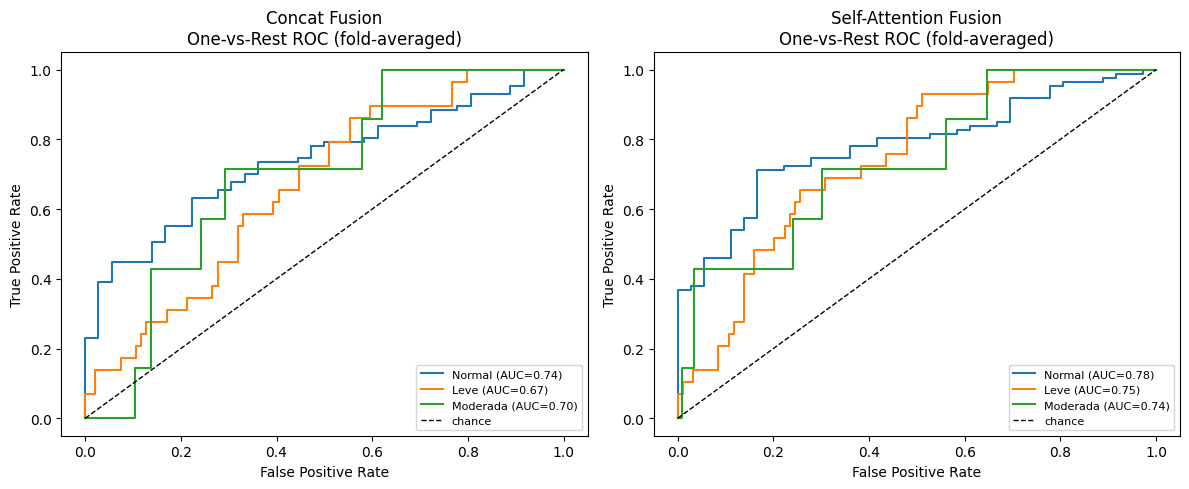

In [38]:
from sklearn.metrics import roc_curve, auc as sk_auc

CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]
true_labels = test_df["Label"].to_numpy()

ensemble_probs = {fusion_name: np.mean(np.stack(fold_test_probs[fusion_name], axis=0), axis=0)
                   for fusion_name in ["concat", "self_attention"]}
ensemble_preds = {fusion_name: probs.argmax(axis=1) for fusion_name, probs in ensemble_probs.items()}
ensemble_cms = {fusion_name: confusion_matrix(true_labels, preds, labels=list(range(NUM_CLASSES)))
                 for fusion_name, preds in ensemble_preds.items()}

# --- Confusion matrices (fold-averaged / ensembled) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, key in [(axes[0], "Concat Fusion", "concat"), (axes[1], "Self-Attention Fusion", "self_attention")]:
    disp = ConfusionMatrixDisplay(confusion_matrix=ensemble_cms[key], display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(fold-averaged, N_FOLDS={N_FOLDS})")
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices_fold_averaged.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

# --- One-vs-rest ROC curves (fold-averaged probabilities) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, key in [(axes[0], "Concat Fusion", "concat"), (axes[1], "Self-Attention Fusion", "self_attention")]:
    probs = ensemble_probs[key]
    y_bin = label_binarize(true_labels, classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], probs[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC={sk_auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}\nOne-vs-Rest ROC (fold-averaged)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
roc_png = os.path.join(RESULTS_DIR, "roc_curves_ovr_fold_averaged.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()

Loss curves — concat vs self_attention (mean across folds)

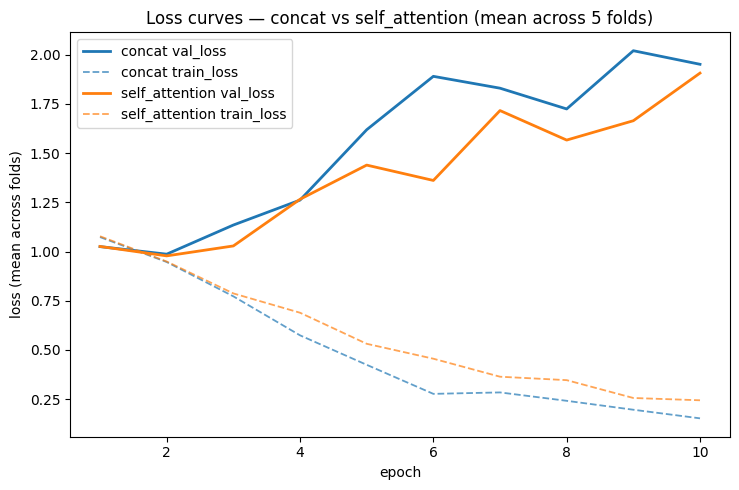

In [39]:
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {"concat": "tab:blue", "self_attention": "tab:orange"}

for fusion_name in ["concat", "self_attention"]:
    hist_df = pd.concat(fold_histories[fusion_name], ignore_index=True)
    mean_val_loss = hist_df.groupby("epoch")["val_loss"].mean()
    mean_train_loss = hist_df.groupby("epoch")["train_loss"].mean()

    ax.plot(mean_val_loss.index, mean_val_loss.values,
            color=colors[fusion_name], linestyle="-", linewidth=2,
            label=f"{fusion_name} val_loss")
    ax.plot(mean_train_loss.index, mean_train_loss.values,
            color=colors[fusion_name], linestyle="--", linewidth=1.3, alpha=0.7,
            label=f"{fusion_name} train_loss")

ax.set_xlabel("epoch")
ax.set_ylabel("loss (mean across folds)")
ax.set_title(f"Loss curves \u2014 concat vs self_attention (mean across {N_FOLDS} folds)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

Per-fold F1 comparison

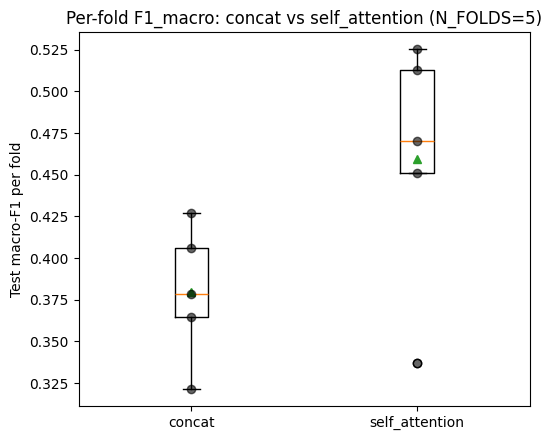

In [40]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
concat_f1 = fold_results_df.loc[fold_results_df["fusion"] == "concat", "f1_macro"].to_numpy()
selfattn_f1 = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", "f1_macro"].to_numpy()
ax.boxplot([concat_f1, selfattn_f1], showmeans=True)
ax.set_xticks([1, 2]); ax.set_xticklabels(["concat", "self_attention"])
for i, scores in enumerate([concat_f1, selfattn_f1], start=1):
    ax.scatter([i] * len(scores), scores, alpha=0.6, color="black", zorder=3)
ax.set_ylabel("Test macro-F1 per fold")
ax.set_title(f"Per-fold F1_macro: concat vs self_attention (N_FOLDS={N_FOLDS})")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "per_fold_f1_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 13 — Final Comparison Table: Concat vs Self-Attention (5-fold)

Fold-averaged (ensemble) test metrics for the two fusion methods on the same fixed test set, plus the mean ± std of macro-F1 across folds.

                     model  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr  f1_macro_cv_mean  f1_macro_cv_std
        deep_concat_fusion  0.634146          0.35346      0.360153  0.356229       0.700635          0.379535         0.040504
deep_self_attention_fusion  0.707317          0.56229      0.446086  0.467707       0.756042          0.459303         0.074708


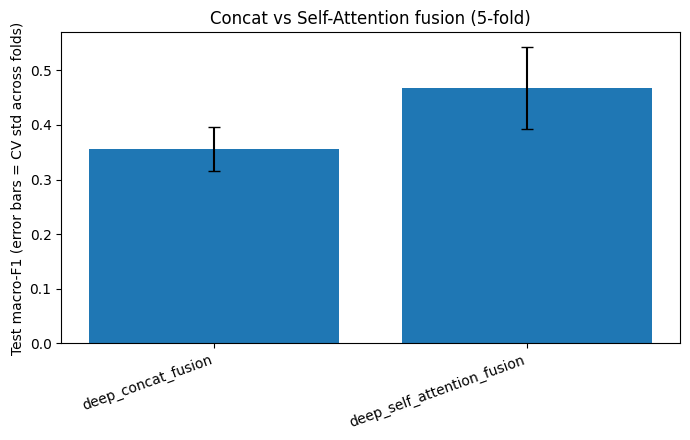


All outputs saved to: /kaggle/working/fydp-3_results/cv_ex1_with_bilstm/2026-10-24


In [41]:
def ensemble_metrics(key):
    probs = ensemble_probs[key]
    preds = probs.argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
        true_labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    try:
        y_bin = label_binarize(true_labels, classes=list(range(NUM_CLASSES)))
        auc_m = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_m = float("nan")
    return {"accuracy": acc, "precision_macro": prec_m, "recall_macro": rec_m,
            "f1_macro": f1_m, "auc_macro_ovr": auc_m}

final_rows = []
for key, label in [("concat", "deep_concat_fusion"), ("self_attention", "deep_self_attention_fusion")]:
    row = {"model": label}
    row.update(ensemble_metrics(key))
    cv_row = cv_summary_df[cv_summary_df["fusion"] == key].iloc[0]
    row["f1_macro_cv_mean"] = cv_row["f1_macro_mean"]
    row["f1_macro_cv_std"] = cv_row["f1_macro_std"]
    final_rows.append(row)

final_compare_df = pd.DataFrame(final_rows)
cols = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr",
        "f1_macro_cv_mean", "f1_macro_cv_std"]
print(final_compare_df[cols].to_string(index=False))
final_compare_df.to_csv(os.path.join(RESULTS_DIR, "final_model_comparison.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(final_compare_df))
ax.bar(x, final_compare_df["f1_macro"], yerr=final_compare_df["f1_macro_cv_std"], capsize=4)
ax.set_xticks(x); ax.set_xticklabels(final_compare_df["model"], rotation=20, ha="right")
ax.set_ylabel("Test macro-F1 (error bars = CV std across folds)")
ax.set_title("Concat vs Self-Attention fusion (5-fold)")
plt.tight_layout()
final_png = os.path.join(RESULTS_DIR, "final_model_comparison_bar.png")
plt.savefig(final_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to:", RESULTS_DIR)

## Step 14 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — per-fold histories/metrics, the CV summary,
the permutation-test result, tabular-baseline results, confusion matrices, ROC curves, the final
comparison table/bar chart, and all per-fold model weights — into a single `.zip` in
`/kaggle/working/`.

In [42]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"fydp-3_ex-1-with-bi-lstm-without-demographic-5fold_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))

Files bundled into the zip:
  concat_cv_history.csv  (3.4 KB)
  concat_fold1_model.pt  (136756.8 KB)
  concat_fold2_model.pt  (136756.8 KB)
  concat_fold3_model.pt  (136756.8 KB)
  concat_fold4_model.pt  (136756.8 KB)
  concat_fold5_model.pt  (136756.8 KB)
  confusion_matrices_fold_averaged.png  (42.9 KB)
  cv_fold_results.csv  (1.3 KB)
  cv_summary_mean_std.csv  (0.6 KB)
  final_model_comparison.csv  (0.4 KB)
  final_model_comparison_bar.png  (48.4 KB)
  loss_curves_comparison.png  (91.6 KB)
  per_fold_f1_comparison.png  (42.9 KB)
  permutation_test_result.json  (0.1 KB)
  roc_curves_ovr_fold_averaged.png  (86.7 KB)
  self_attention_cv_history.csv  (3.8 KB)
  self_attention_fold1_model.pt  (138506.1 KB)
  self_attention_fold2_model.pt  (138506.1 KB)
  self_attention_fold3_model.pt  (138506.1 KB)
  self_attention_fold4_model.pt  (138506.1 KB)
  self_attention_fold5_model.pt  (138506.1 KB)

Zip written to: /kaggle/working/fydp-3_ex-1-with-bi-lstm-without-demographic-5fold_results_2026-1

/kaggle/working/fydp-3_ex-1-with-bi-lstm-without-demographic-5fold_results_2026-10-24.zip